In [1]:
!pip -q install librosa soundfile seaborn

In [2]:
!wget -q --show-progress https://data.keithito.com/data/speech/LJSpeech-1.1.tar.bz2
!tar -xjf LJSpeech-1.1.tar.bz2
!ls LJSpeech-1.1 | head

LJSpeech-1.1.tar.bz 100%[===================>]   2.56G  87.9MB/s    in 35s     
metadata.csv
README
wavs


In [3]:
import numpy as np, pandas as pd, librosa, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from scipy.signal import medfilt

ROOT = Path("LJSpeech-1.1"); WAV = ROOT / "wavs"
meta = pd.read_csv(ROOT / "metadata.csv", sep="|", header=None, quoting=3,
                   names=["id", "raw", "text"])
meta["text"] = meta["text"].fillna(meta["raw"]).astype(str).str.strip()
meta["n_words"] = meta["text"].str.split().str.len()

meta["label"] = np.where(meta.text.str.endswith("?"), "question",
                 np.where(meta.text.str.endswith("."), "statement", "other"))

# keep short/medium sentences so length doesn't differ wildly between classes
meta = meta[(meta.label != "other") & meta.n_words.between(4, 15)].reset_index(drop=True)

# wh-questions vs yes/no questions (they behave differently in English)
WH = ("what","who","whom","whose","where","when","why","which","how")
first = meta.text.str.split().str[0].str.lower().str.strip('"\'')
meta["qtype"] = np.where(meta.label == "statement", "statement",
                 np.where(first.isin(WH), "wh-question", "yes/no-question"))

print(meta.label.value_counts())
print(meta.qtype.value_counts())

label
statement    2901
question       28
Name: count, dtype: int64
qtype
statement          2901
yes/no-question      19
wh-question           9
Name: count, dtype: int64


In [4]:
SR, HOP, FRAME = 16000, 256, 1024   # 16 ms hop

def load_clip(clip_id):
    y, _ = librosa.load(WAV / f"{clip_id}.wav", sr=SR)
    return y

def prosody_contours(y):
    f0, voiced, _ = librosa.pyin(y, fmin=70, fmax=400, sr=SR,
                                 frame_length=FRAME, hop_length=HOP)
    rms = librosa.feature.rms(y=y, frame_length=FRAME, hop_length=HOP)[0]
    energy_db = librosa.amplitude_to_db(rms, ref=np.max)
    n = min(len(f0), len(energy_db))
    t = librosa.times_like(f0[:n], sr=SR, hop_length=HOP)
    return t, f0[:n], energy_db[:n]

def pause_info(y, min_pause=0.15, top_db=35):
    iv = librosa.effects.split(y, top_db=top_db, frame_length=FRAME, hop_length=HOP)
    span = (iv[-1, 1] - iv[0, 0]) / SR
    gaps = (iv[1:, 0] - iv[:-1, 1]) / SR
    pauses = gaps[gaps >= min_pause]
    return iv, span, pauses

def voiced_semitones(t, f0):
    m = ~np.isnan(f0)
    tv, fv = t[m], f0[m]
    if len(fv) < 8:
        return tv, np.array([])
    st = 12 * np.log2(fv / np.median(fv))
    return tv, medfilt(st, 5)          # removes octave-jump glitches

def extract_features(clip_id, n_words):
    y = load_clip(clip_id)
    t, f0, e = prosody_contours(y)
    tv, st = voiced_semitones(t, f0)
    iv, span, pauses = pause_info(y)

    feats = dict(id=clip_id, duration=len(y) / SR)
    if len(st) >= 8:
        feats["f0_mean_hz"] = float(np.nanmean(f0))
        feats["f0_std_st"] = float(np.std(st))
        feats["f0_range_st"] = float(np.percentile(st, 95) - np.percentile(st, 5))
        feats["initial_level_st"] = float(np.mean(st[:5]))
        feats["final_level_st"] = float(np.mean(st[-5:]))
        sel = tv >= tv[-1] - 0.4
        feats["final_slope_st_per_s"] = (float(np.polyfit(tv[sel], st[sel], 1)[0])
                                         if sel.sum() >= 4 else np.nan)
    feats["energy_std_db"] = float(np.std(e[e > -50]))
    feats["n_pauses"] = int(len(pauses))
    feats["pause_ratio"] = float(pauses.sum() / span) if span > 0 else 0.0
    feats["speaking_rate_wps"] = n_words / span
    feats["articulation_rate_wps"] = n_words / max(span - pauses.sum(), 1e-3)
    return feats

# quick test on one clip
r = meta.iloc[0]
extract_features(r.id, r.n_words)

{'id': 'LJ001-0002',
 'duration': 1.8995625,
 'f0_mean_hz': 240.21711029859947,
 'f0_std_st': 4.718005353455573,
 'f0_range_st': 12.700000000000001,
 'initial_level_st': 6.379999999999998,
 'final_level_st': -3.000000000000001,
 'final_slope_st_per_s': -2.8751717032967057,
 'energy_std_db': 8.95000171661377,
 'n_pauses': 0,
 'pause_ratio': 0.0,
 'speaking_rate_wps': np.float64(2.1929824561403506),
 'articulation_rate_wps': np.float64(2.1929824561403506)}

In [5]:
rng = np.random.default_rng(42)
nq = (meta.label == "question").sum()
q = meta[meta.label == "question"].sample(min(150, nq), random_state=42)

pool = meta[meta.label == "statement"]
chosen = []
for nw in q.n_words:
    cand = pool[(pool.n_words == nw) & ~pool.id.isin(chosen)]
    if len(cand) == 0:
        continue
    chosen.append(cand.sample(1, random_state=int(rng.integers(10**9))).id.iloc[0])
s = pool[pool.id.isin(chosen)]

data = pd.concat([q, s]).reset_index(drop=True)
data["y"] = (data.label == "question").astype(int)
print(data.label.value_counts())
print("mean words per class:", data.groupby("label").n_words.mean().round(2).to_dict())

label
question     28
statement    28
Name: count, dtype: int64
mean words per class: {'question': 10.0, 'statement': 10.0}


In [6]:
from joblib import Parallel, delayed
rows = Parallel(n_jobs=-1)(delayed(extract_features)(r.id, r.n_words) for r in data.itertuples())
feats = pd.DataFrame(rows)
df = data[["id", "text", "label", "y", "qtype"]].merge(feats, on="id")
df.to_csv("prosody_features.csv", index=False)
print(df.shape)
df.groupby("label").mean(numeric_only=True).T.round(2)

(56, 17)


label,question,statement
y,1.00,0.00
duration,3.50,4.26
f0_mean_hz,228.01,219.35
f0_std_st,3.10,3.51
f0_range_st,9.98,11.32
initial_level_st,2.06,2.54
final_level_st,3.17,-0.97
final_slope_st_per_s,11.64,3.95
energy_std_db,10.87,11.05
n_pauses,0.43,0.89


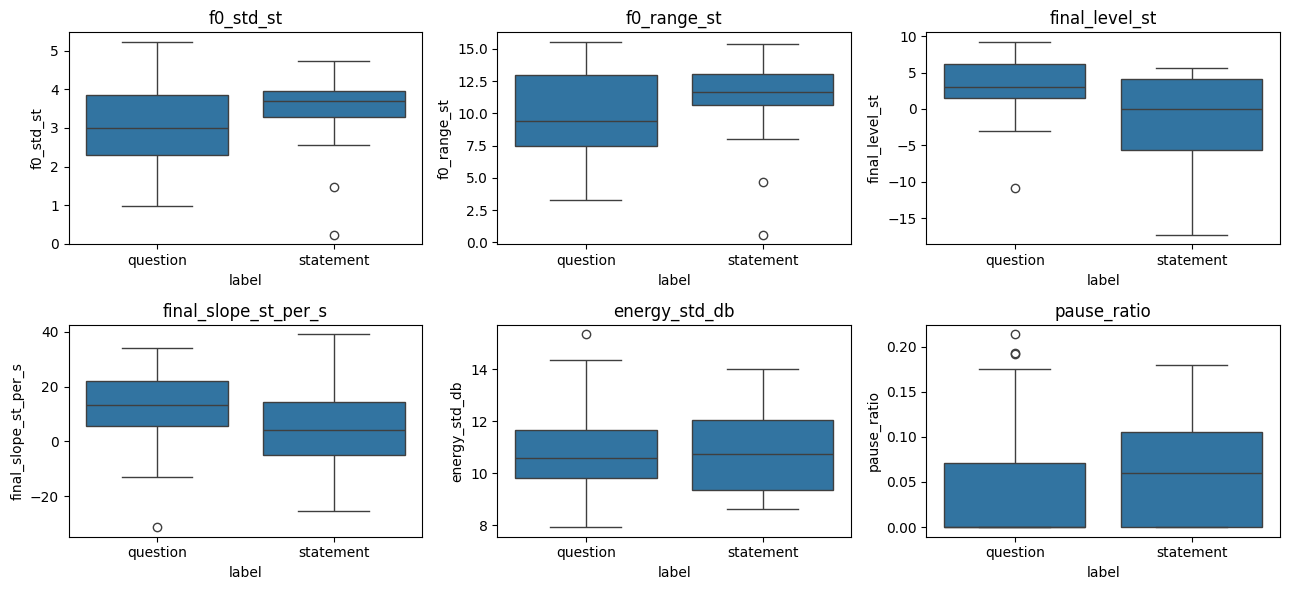

In [7]:
cols = ["f0_std_st", "f0_range_st", "final_level_st", "final_slope_st_per_s",
        "energy_std_db", "pause_ratio"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, c in zip(axes.ravel(), cols):
    sns.boxplot(data=df, x="label", y=c, ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.savefig("feature_boxplots.png", dpi=150); plt.show()

In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict

FEATURES = ["f0_mean_hz", "f0_std_st", "f0_range_st", "initial_level_st", "final_level_st",
            "final_slope_st_per_s", "energy_std_db", "n_pauses", "pause_ratio",
            "speaking_rate_wps", "articulation_rate_wps"]
X, y = df[FEATURES], df["y"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Logistic Regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                         LogisticRegression(max_iter=1000)),
    "Random Forest": make_pipeline(SimpleImputer(strategy="median"),
                                   RandomForestClassifier(n_estimators=300, random_state=42)),
}
results = {}
for name, m in models.items():
    sc = cross_val_score(m, X, y, cv=cv, scoring="accuracy")
    results[name] = (sc.mean(), sc.std())
    print(f"{name}: {sc.mean():.3f} +/- {sc.std():.3f}")
print("Majority-class baseline: 0.500 (balanced data)")

# ablation: only end-of-utterance pitch features
ends = ["final_level_st", "final_slope_st_per_s"]
sc = cross_val_score(models["Random Forest"], df[ends], y, cv=cv)
print(f"RF with only final-pitch features: {sc.mean():.3f} +/- {sc.std():.3f}")

Logistic Regression: 0.732 +/- 0.100
Random Forest: 0.732 +/- 0.100
Majority-class baseline: 0.500 (balanced data)
RF with only final-pitch features: 0.788 +/- 0.130


              precision    recall  f1-score   support

   statement       0.71      0.79      0.75        28
    question       0.76      0.68      0.72        28

    accuracy                           0.73        56
   macro avg       0.73      0.73      0.73        56
weighted avg       0.73      0.73      0.73        56



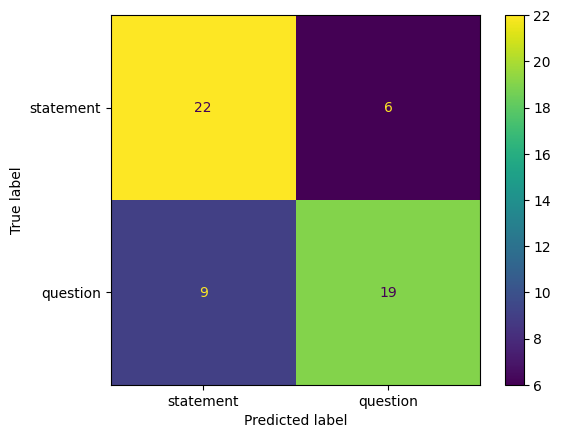

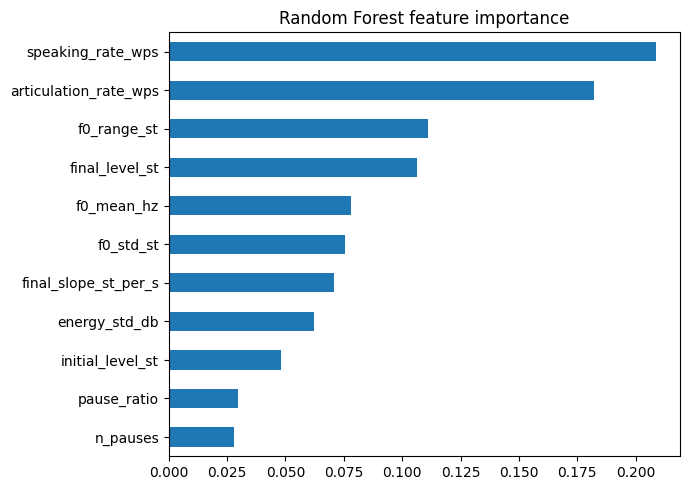

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
rf = models["Random Forest"]
pred = cross_val_predict(rf, X, y, cv=cv)
print(classification_report(y, pred, target_names=["statement", "question"]))
ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=["statement", "question"])
plt.savefig("confusion_matrix.png", dpi=150); plt.show()

rf.fit(X, y)
imp = pd.Series(rf[-1].feature_importances_, index=FEATURES).sort_values()
imp.plot.barh(figsize=(7, 5), title="Random Forest feature importance")
plt.tight_layout(); plt.savefig("feature_importance.png", dpi=150); plt.show()

In [10]:
df["pred"] = pred
print(df[df.y == 1].groupby("qtype").apply(lambda g: (g.pred == 1).mean()).rename("recall"))
print(df[df.y == 1].qtype.value_counts())

qtype
wh-question        0.444444
yes/no-question    0.789474
Name: recall, dtype: float64
qtype
yes/no-question    19
wh-question         9
Name: count, dtype: int64


/tmp/ipykernel_26469/3517918680.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(df[df.y == 1].groupby("qtype").apply(lambda g: (g.pred == 1).mean()).rename("recall"))


In [11]:
print(f"Clips used: {len(df)}  (questions: {(df.y==1).sum()}, statements: {(df.y==0).sum()})")
for k, (m_, s_) in results.items():
    print(f"{k}: {m_*100:.1f}% +/- {s_*100:.1f}% (5-fold CV)")
print("Top 3 features:", list(imp.sort_values(ascending=False).index[:3]))

from google.colab import files
for f in ["prosody_features.csv", "feature_boxplots.png", "confusion_matrix.png", "feature_importance.png"]:
    files.download(f)

Clips used: 56  (questions: 28, statements: 28)
Logistic Regression: 73.2% +/- 10.0% (5-fold CV)
Random Forest: 73.2% +/- 10.0% (5-fold CV)
Top 3 features: ['speaking_rate_wps', 'articulation_rate_wps', 'f0_range_st']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>